# 06 — Energy flows

**Concept:** a bill charges **flows**, not "consumption". At a site's meter, energy is **imported**, **exported**, or produced and used on site (**self-consumption**, never seen by the meter). A sharing scheme allocates parts of the import or export to **counterparties** (**shared in / out**); what remains is **supplied** by the supplier or **sold** to the grid buyer.

**You will learn:** how a site is described as data (assets by kind), how flows are computed from the assets' roles, why the time step changes self-consumption, how shared energy splits the import, and how a new kind of asset joins without code changes.

## A site, described as data

A site file lists the contract (under a tariff pack, notebook 05) and the assets by **kind**. Flows only look at each kind's **role**: a source produces, a sink consumes, a storage does either.

In [1]:
import warnings
from datetime import datetime, timedelta
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np

from myenergy.adapters.packs.toml_files import TomlPackSource, builtin_packs
from myenergy.adapters.profiles.memory import InMemoryProfileSource
from myenergy.adapters.profiles.synthetic import SyntheticProfileSource
from myenergy.adapters.sites.toml_files import load_sites
from myenergy.domain.flows import FlowKind
from myenergy.domain.profiles import ProfileKind, ProfileMeta, ProfileUnit, TimestampLabel
from myenergy.domain.series import Quantity, TimeSeries
from myenergy.domain.sites import AssetRole
from myenergy.domain.time import TimeGrid
from myenergy.engine.assets import CONSUMER, PV
from myenergy.engine.profiles import ProfileResolver
from myenergy.engine.sites import SiteResolver

PARIS = ZoneInfo("Europe/Paris")
packs = TomlPackSource([builtin_packs()])
SITE = '''
[sites.home]
pack = "fr-household"

[sites.home.contract]
subscribed_kva = 6
off_peak = "22:00-06:00"
fields = { fta = "CU4", supply_option = "hp-hc" }

[[sites.home.assets]]
id = "house"
kind = "consumer"
profile = { source = "synthetic", key = "household", annual_kwh = 3500 }

[[sites.home.assets]]
id = "roof"
kind = "pv"
profile = { source = "synthetic", key = "pv-clear-sky", peak_kwp = 3, yield_kwh_per_kwp = 1100 }
'''
home = load_sites(SITE, packs)["home"]
kinds = {"consumer": CONSUMER, "pv": PV}
profiles = ProfileResolver({"synthetic": SyntheticProfileSource(seed=1)})
sites = SiteResolver(kinds, profiles, packs)

week = TimeGrid(start=datetime(2026, 6, 1, tzinfo=PARIS), end=datetime(2026, 6, 8, tzinfo=PARIS),
                step=timedelta(minutes=15))
flows = sites.flows(home, week)
for kind, kwh in flows.totals().items():
    print(f"{kind.value:17} {kwh:7.2f} kWh")

import              22.41 kWh
export              74.58 kWh
self_consumption    32.14 kWh
shared_in            0.00 kWh
shared_out           0.00 kWh
supplied            22.41 kWh
sold                74.58 kWh


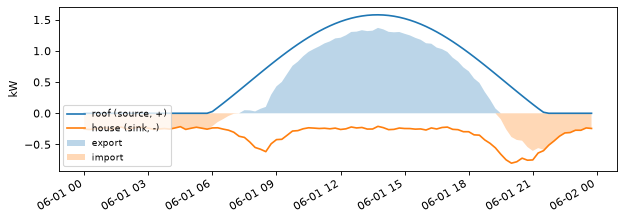

In [2]:
powers = sites.powers(home, week)
day = slice(0, 96)
hours = [week.local(i) for i in range(96)]
fig, ax = plt.subplots(figsize=(9, 3), dpi=80)
ax.plot(hours, powers["roof"].values[day], label="roof (source, +)")
ax.plot(hours, powers["house"].values[day], label="house (sink, -)")
ax.fill_between(hours, 0, flows.exported.values[day] / week.step_hours, alpha=0.3, label="export")
ax.fill_between(hours, 0, -flows.imported.values[day] / week.step_hours, alpha=0.3, label="import")
ax.set_ylabel("kW")
ax.legend(loc="lower left", fontsize=8)
fig.autofmt_xdate()

## The time step changes self-consumption

Flows compare production and consumption **per step**. A kettle that runs for 5 minutes while the sun is behind a cloud really imports; averaged over 30 minutes, the same kettle looks covered by the sun. Coarse steps therefore show **more self-consumption** than really happens. A home meter records import and export almost instantly; simulations on 30-minute profiles carry this bias. Here, a measured 5-minute day with bursts:

In [3]:
start = datetime(2026, 6, 1, tzinfo=PARIS)
fine = TimeGrid(start=start, end=start + timedelta(days=1), step=timedelta(minutes=5))
steps = np.arange(len(fine))
rng = np.random.default_rng(3)
hour = (steps * 5 / 60)
sun = np.clip(np.sin((hour - 6) / 14 * np.pi), 0, None) * 2.5
clouds = np.where(rng.random(len(fine)) < 0.25, 0.2, 1.0)
pv_kw = sun * clouds
load_kw = 0.3 + np.where(rng.random(len(fine)) < 0.08, 2.0, 0.0)


def measured(key: str, values: np.ndarray, kind: ProfileKind):
    meta = ProfileMeta(key=key, kind=kind, coverage=fine, label=TimestampLabel.START,
                       description=key, unit=ProfileUnit.KW)
    return meta, TimeSeries(grid=fine, values=values, quantity=Quantity.DIMENSIONLESS)


meter = InMemoryProfileSource("meter", {
    "load": measured("load", load_kw, ProfileKind.CONSUMPTION),
    "pv": measured("pv", pv_kw, ProfileKind.PRODUCTION),
    "op": measured("op", np.where((hour < 6) | (hour >= 20), 0.3, 0.0), ProfileKind.CONSUMPTION),
})
MEASURED = '''
[sites.bursty]
pack = "fr-household"
[sites.bursty.contract]
subscribed_kva = 6
fields = { fta = "LU", supply_option = "base", status = "collective" }
[[sites.bursty.assets]]
id = "house"
kind = "consumer"
profile = { source = "meter", key = "load", as_measured = true }
[[sites.bursty.assets]]
id = "roof"
kind = "pv"
profile = { source = "meter", key = "pv", as_measured = true }
'''
bursty = load_sites(MEASURED, packs)["bursty"]
sites = SiteResolver(kinds, ProfileResolver({"meter": meter}), packs)
for minutes in (5, 15, 30, 60):
    totals = sites.flows(bursty, fine.with_step(timedelta(minutes=minutes))).totals()
    print(f"{minutes:>2}-minute steps: self-consumption {totals[FlowKind.SELF_CONSUMPTION]:5.2f} kWh, "
          f"import {totals[FlowKind.IMPORT]:5.2f}, export {totals[FlowKind.EXPORT]:5.2f}")

 5-minute steps: self-consumption  5.75 kWh, import  7.12, export 12.83
15-minute steps: self-consumption  6.55 kWh, import  6.32, export 12.02
30-minute steps: self-consumption  6.79 kWh, import  6.07, export 11.78
60-minute steps: self-consumption  6.86 kWh, import  6.00, export 11.71


Import minus export, the net energy, is the same at every step; only the split between self-consumption and import/export moves.

## Shared energy

A collective operation allocates part of the site's import to it (French *autoproduite*); the supplier sells the rest (*alloproduite*). Here the operation's small wind turbine is allocated 0.3 kW to this home in the evening and at night. An allocation can never exceed what the meter imports: that would be an error naming the step. The French pack allocates per 30 minutes (to verify): computing flows on another step raises a warning.

In [4]:
shared = MEASURED + '''
[[sites.bursty.shares]]
direction = "in"
counterparty = "street-operation"
profile = { source = "meter", key = "op", as_measured = true }
'''
member = load_sites(shared, packs)["bursty"]
half_hour = fine.with_step(timedelta(minutes=30))
flows = sites.flows(member, half_hour)
for kind in (FlowKind.IMPORT, FlowKind.SHARED_IN, FlowKind.SUPPLIED):
    print(f"{kind.value:10} {flows.totals()[kind]:5.2f} kWh")
print("counterparties:", {d.value: c for d, c in flows.counterparties.items()})
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    sites.flows(member, fine.with_step(timedelta(minutes=15)))
print(caught[0].message)

import      6.07 kWh
shared_in   3.00 kWh
supplied    3.07 kWh
counterparties: {'in': ('street-operation',), 'out': ()}
site 'bursty': pack 'fr-household' allocates shared energy every 0:30:00, but flows are computed every 0:15:00


## A new kind of asset, without changing any code

Kinds are plugins: anything with a `name`, a `role` and a `power()` method. Installed packages register them as entry points (`myenergy.asset_kinds`); here a toy electric car that charges at 7 kW from 01:00 to 03:00 is passed directly. The site file just names it.

In [5]:
class NightCharger:
    name = "ev"
    role = AssetRole.SINK

    def power(self, asset, grid, profiles):
        local_hours = np.array([grid.local(i).hour for i in range(len(grid))])
        values = np.where((local_hours >= 1) & (local_hours < 3), 7.0, 0.0)
        return TimeSeries(grid=grid, values=values, quantity=Quantity.POWER_KW)


with_car = MEASURED + '''
[[sites.bursty.assets]]
id = "car"
kind = "ev"
'''
site = load_sites(with_car, packs)["bursty"]
sites = SiteResolver(kinds | {"ev": NightCharger()}, ProfileResolver({"meter": meter}), packs)
totals = sites.flows(site, half_hour).totals()
print(f"import with the car: {totals[FlowKind.IMPORT]:.2f} kWh (14 kWh more at night)")

import with the car: 20.07 kWh (14 kWh more at night)


**Next:** the anatomy of a bill (M2) prices these flows: each line of a price book names the flow and the schedule periods it charges.